#Prediction of Price

Question: Is it possible to predict price of a car?

Answer: Yes and No (Jein). It depends on the goal.
If we need an exact price prediction, then the answer is no, because even our best model has an RMSE of about 113 000 .
 But if we only need a rough estimate of the car’s price range, then the model is good enough.

# What data do we have, and what should we do?

First, we import the necessary Python libraries, examine the dataset to see how many categorical and numerical features it contains, and check for missing values.

In [ ]:
import numpy as np
import pandas as pd

import pandas as pd
df = pd.read_csv('topic21_v33_train.csv')
print(df.head())
null_cols = df.columns[df.isnull().any()]
print(null_cols.tolist())

          0         1         2          3         4          brand  \
0 -6.256711  0.688300  2.297675  -3.367932  1.449606  Mercedes-Benz   
1 -4.796051  0.616683  2.435286   3.297900  1.894906        Lincoln   
2 -4.844841  0.347689  1.989259 -10.118850       NaN           Jeep   
3 -3.360542  9.996611  2.258961  -8.809904  0.240771            BMW   
4 -1.478214  2.682461  2.003860  -2.172707  5.652469            BMW   

       model       trim body_type fuel_type       transmission_type  \
0        GLA        200       SUV    Petrol  Automatic Transmission   
1  Navigator      L AWD       SUV    Petrol  Automatic Transmission   
2   Wrangler    Rubicon       SUV    Petrol  Automatic Transmission   
3   7-Series      740LE     Sedan    Hybrid  Automatic Transmission   
4         X5  Xdrive50i       SUV    Petrol  Automatic Transmission   

  engine_capacity_cc    horsepower exterior_color interior_color warranty  \
0     1000 - 1499 cc  200 - 299 HP          White        Unknown     

Let's split the data set into train and test sets.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df['price'] = df['price'].astype(float)
x = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(x, y, train_size=0.8, shuffle=True, random_state=42)

Let's see how many value there are in categorical features. Note that there are too many values in 'brand', 'model', and 'trim'. We will deal with this in the next section.

In [ ]:
categorical_features = [
    'brand','model','trim','body_type','fuel_type',
    'transmission_type','exterior_color','interior_color',
    'warranty','city','seller_type'
]

for feature in categorical_features:
    print(X_train[feature].value_counts())
    print()

brand
Mercedes-Benz    999
BMW              548
Nissan           451
Land Rover       448
Toyota           447
                ... 
Exeed              1
Chery              1
KTM                1
Bugatti            1
Soueast            1
Name: count, Length: 86, dtype: int64

model
Range Rover          182
S-Class              156
Range Rover Sport    127
C-Class              126
G-Class              116
                    ... 
Icona                  1
Groove                 1
Shelby Cobra           1
SLC                    1
Colorado               1
Name: count, Length: 587, dtype: int64

trim
Other               1268
Standard             278
S                    187
SE                   141
G 63 AMG              98
                    ... 
HSE Royal              1
LP 700-4               1
Advanced               1
High Line              1
F Sport Prestige       1
Name: count, Length: 720, dtype: int64

body_type
SUV                     2920
Sedan                   1757
Coupe          

As we are going to transform string features 'engine_capacity_cc', and 'horsepower' into numeric features, we check how missing values are encoded. We see that except simple NaN we also have 'Unknown' which we will further encode as NaN

In [ ]:
cols = ['engine_capacity_cc', 'horsepower']

for col in cols:
    print()
    print(col)
    print(df[col].dropna().unique())


engine_capacity_cc
['1000 - 1499 cc' '4000+ cc' '2000 - 2499 cc' '2500 - 2999 cc'
 '3500 - 3999 cc' '1500 - 1999 cc' '0 - 499 cc' '3000 - 3499 cc' 'Unknown'
 '500 - 999 cc']

horsepower
['200 - 299 HP' '500 - 599 HP' '400 - 499 HP' 'Unknown' '300 - 399 HP'
 '800 - 899 HP' '100 - 199 HP' '600 - 699 HP' '700 - 799 HP' '0 - 99 HP'
 '900+ HP']


Let's train a naive linear regression model at first as a baseline model. In the following, we handle categorical features using OneHotEncoder and encode 'engine_capacity_cc', and 'horsepower' via the following pattern:

1000 - 1499 cc -> 1250

4000+ cc -> 4000

200 - 299 HP -> 250

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.impute import SimpleImputer # Import SimpleImputer
from sklearn.preprocessing import FunctionTransformer

categorical_features_one_hot_encoding = [
    'brand','model','trim','body_type','fuel_type',
    'transmission_type','exterior_color','interior_color',
    'warranty','city','seller_type'
]

numeric_features = ['0','1','2','3','4','engine_capacity_cc','horsepower']

def parse_value(val, suffix):
    if pd.isna(val):
        return np.nan

    s = str(val).replace(suffix, '').strip()
    if s in ['Unknown']:
        return np.nan
    if '+' in s:
        return int(s.replace('+', '').strip())
    if '-' in s:
        low, high = s.split('-')
        return (float(low) + float(high)) / 2

    return float(s)

def parse_numeric_cols(X):
    X2 = X.copy()
    X2['engine_capacity_cc'] = X2['engine_capacity_cc'].apply(lambda v: parse_value(v, 'cc'))
    X2['horsepower']         = X2['horsepower'].apply(lambda v: parse_value(v, 'HP'))
    return X2

parse_t = FunctionTransformer(parse_numeric_cols, validate=False)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imp",   SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

pipeline = Pipeline([
    ("parse", parse_t),
    ("prep",  preprocessor),
    ("rf",    LinearRegression())
])

scores = cross_val_score(pipeline, X_train, y_train)

pipeline.fit(X_train, y_train)
train_score = pipeline.score(X_train, y_train)
test_score = pipeline.score(X_test, y_test)

print("CV scores:", scores)
print("mean   CV score :", np.mean(scores))
print("std of CV scores:", np.std(scores))
print("R² on train set:", train_score)
print("R² on test  set:", test_score)

CV scores: [ 4.27631333e-01 -1.54039273e+07  4.57001396e-01  5.19330490e-01
  4.77360505e-01]
mean   CV score : -3080785.0744845783
std of CV scores: 6161571.089631019
R² on train set: 0.6577272300045827
R² on test  set: 0.48922184603662466


We observe such low scores because there is a large number of outliers present in the data. In the following section, we will address and handle these outliers but at first, we'll do some feature engineering to address unrealistic prices and categorical features with many possible values.

## Feature engineering

As seen from the previous section, there are too many unique categories in features 'brand', 'model', and 'trim'. We want to use only the most common of them.

##Unrealisitc prices

<Axes: >

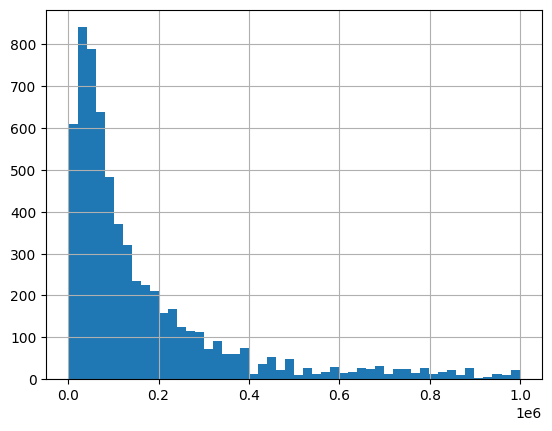

In [ ]:
y_train.hist(bins=50)

After a detailed study of the dataset, we saw that the cheapest cars are luxury cars and their low price seems weird. In order to confirm the suspicions, let's plot the names of all brands up to 4000 and up to 7000 (dollars). As we can see, the price of some brands of cars over 7000 is believable, but brands up to 4000 are exclusively luxury. Let's study in detail whether the price is so low for all cars of these luxury brands, and if not, delete these extremely low-priced cars from the dataset.

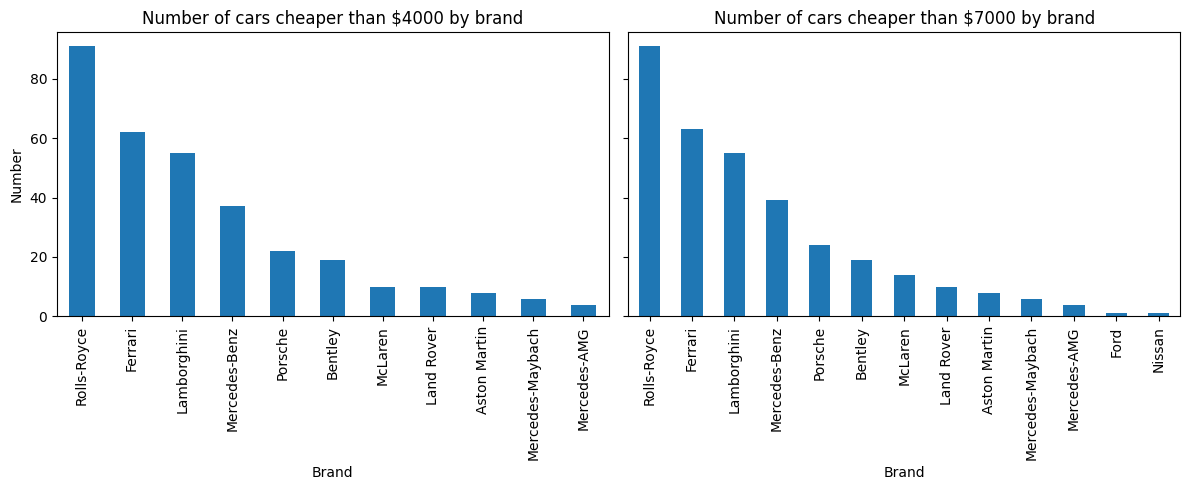

In [ ]:
cheap_cars = []

train_df = pd.concat([X_train, y_train], axis=1)
cheap_cars_4000 = train_df[train_df['price'] < 4000]
cheap_cars_7000 = train_df[train_df['price'] < 7000]

cheap_cars.append(cheap_cars_4000['brand'].value_counts())
cheap_cars.append(cheap_cars_7000['brand'].value_counts())

titles = ['Number of cars cheaper than $4000 by brand', 'Number of cars cheaper than $7000 by brand']

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for i in range(2):
    cheap_cars[i].plot(kind='bar', ax=axes[i])
    axes[i].set_title(titles[i])
    axes[i].set_xlabel('Brand')
    axes[i].set_ylabel('Number')
    axes[i].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

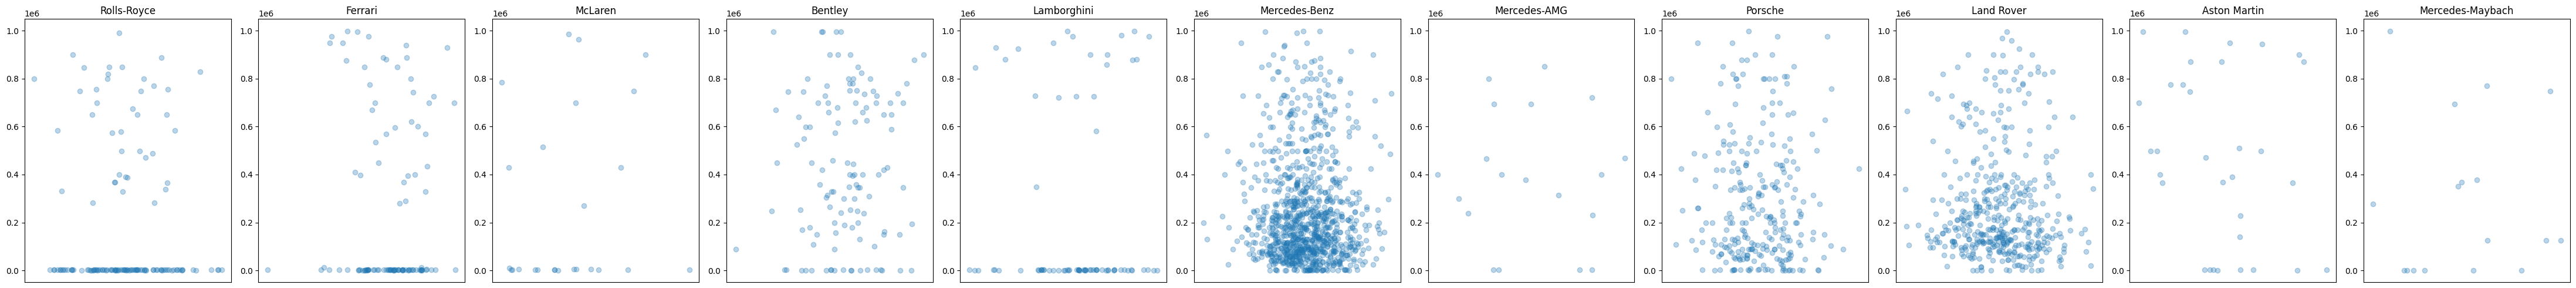

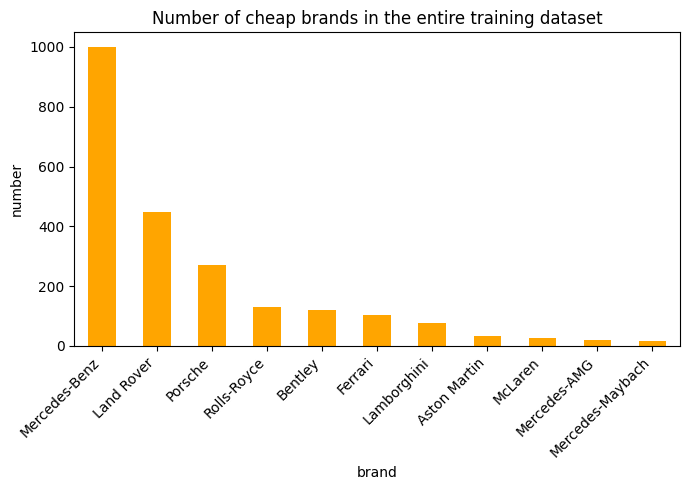

In [ ]:
cheap_brands = cheap_cars_4000['brand'].unique()

cheap_df = train_df[train_df['brand'].isin(cheap_brands)]

n = len(cheap_brands)

fig, axes = plt.subplots(1, n, figsize=(4 * n, 5), sharey=True)

for i, brand in enumerate(cheap_brands):
    ax = axes[i]
    brand_df = cheap_df[cheap_df['brand'] == brand]
    jitter_x = np.random.normal(loc=0, scale=0.1, size=len(brand_df))
    ax.scatter(jitter_x, brand_df['price'], alpha=0.3)
    ax.set_title(brand)
    ax.set_xticks([])
    ax.set_xlabel('')
    ax.tick_params(axis='y', which='both', left=True, labelleft=True)

plt.tight_layout()
plt.show()

cheap_brands_counts = X_train[X_train['brand'].isin(cheap_brands)]['brand'].value_counts()
plt.figure(figsize=(7, 5))
cheap_brands_counts.plot(kind='bar', color='orange')

plt.title('Number of cheap brands in the entire training dataset')
plt.xlabel('brand')
plt.ylabel('number')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
brands_to_keep = ['Rolls-Royce', 'Ferrari', 'Lamborghini']
number = 4000
for i in range(3):
  print(brands_to_keep[i])
  print("number of cars lower than 4000:", len(train_df[(train_df['brand'] == brands_to_keep[i]) & (train_df['price'] < number)]))
  print("number of cars higher than 4000:", len(train_df[(train_df['brand'] == brands_to_keep[i]) & (train_df['price'] > number)]))
  print()


Rolls-Royce
number of cars lower than 4000: 91
number of cars higher than 4000: 40

Ferrari
number of cars lower than 4000: 62
number of cars higher than 4000: 41

Lamborghini
number of cars lower than 4000: 55
number of cars higher than 4000: 21



As we can see, there are more cheap cars of brands Rolls-Royce, Ferrary, and Lamborghini than expensive ones. Therefore we don't delete them. As we can see from the graphs from above, we can't say the same about other brands - there is a significantly lower number of cheap cars as oppsed to expensive ones. Therefore, we delete the cheap cars of those brands from the dataset.

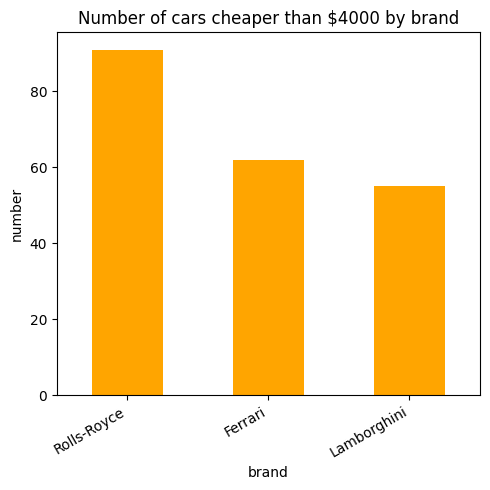

In [ ]:
all_brands = X_train['brand'].unique()
brands_to_change = [b for b in all_brands if b not in brands_to_keep]

condition = ~((train_df['brand'].isin(brands_to_change)) & (train_df['price'] < 4000))
train_df_changed = train_df[condition]
X_train = train_df_changed.drop(columns=['price'])
y_train = train_df_changed['price']

cheap_cars_changed = train_df_changed[train_df_changed['price'] < 4000]['brand'].value_counts()
plt.figure(figsize=(5, 5))
cheap_cars_changed.plot(kind='bar', color='orange')
plt.title('Number of cars cheaper than $4000 by brand')
plt.xlabel('brand')
plt.ylabel('number')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

##Handling outliers in numerical features

Let's analyze outliers in numeric features. Firstly, we plot boxplots

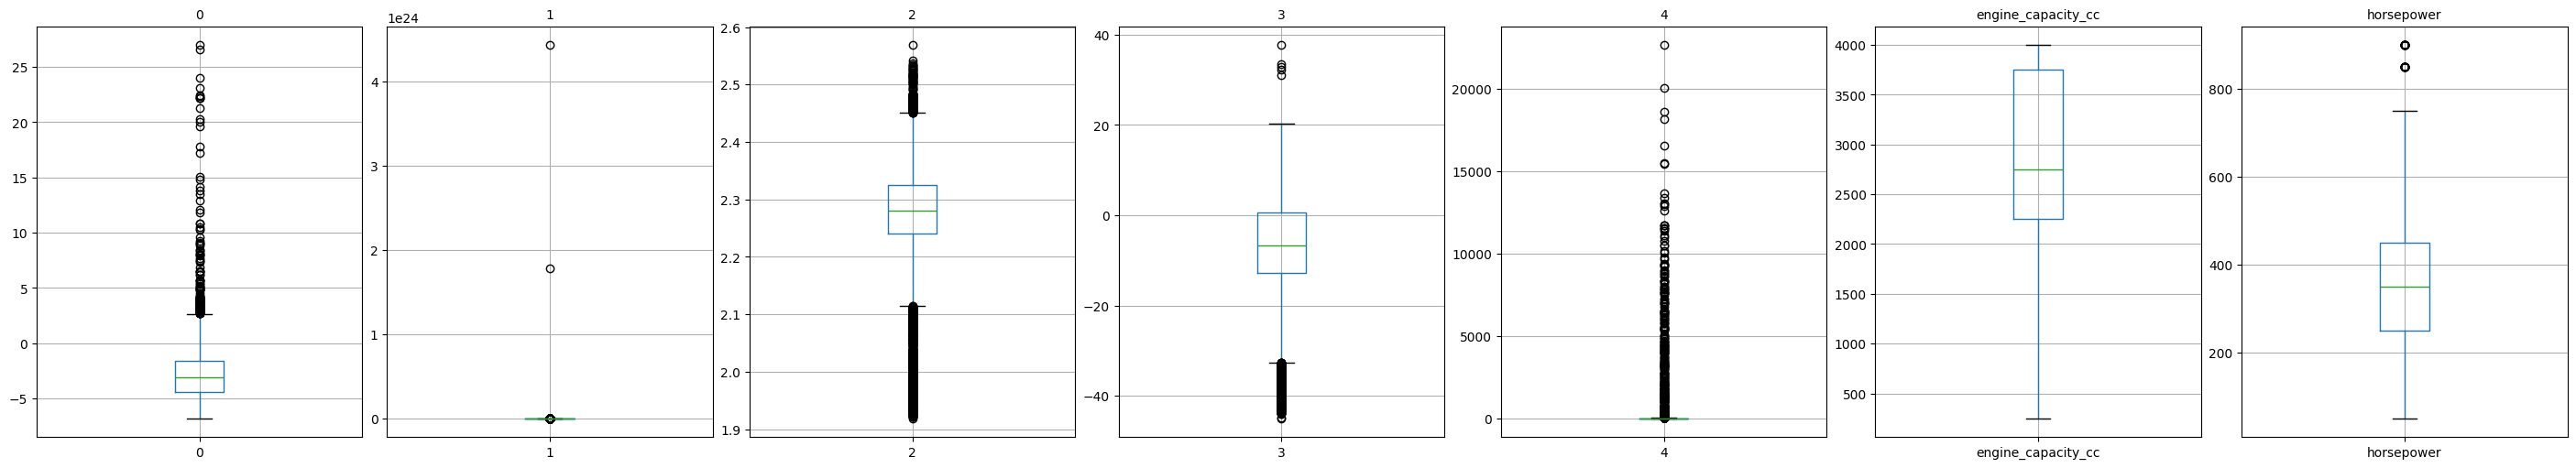

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

numeric_features = ['0','1','2','3','4','engine_capacity_cc','horsepower']
categorical_features = [
    'brand','model','trim','body_type','fuel_type',
    'transmission_type','exterior_color','interior_color',
    'warranty','city','seller_type'
]

X_train_num_transformed = parse_numeric_cols(X_train.copy())

num_cols = len(numeric_features)

fig, axes = plt.subplots(1, num_cols, figsize=(4*num_cols, 5), constrained_layout=True)

for ax, col in zip(axes, numeric_features):
    X_train_num_transformed.boxplot(column=col, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis='x')

plt.show()

We see that there are a lot of outliers in columns 1-4. Let's count their number.

In [ ]:
columns = ['0', '1', '2', '3', '4']

outliers_flags = pd.DataFrame(columns=columns)

for col in columns:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    is_outlier = (X_train[col] < lower_bound) | (X_train[col] > upper_bound)
    outliers_flags[col] = is_outlier

print(outliers_flags.sum())

0    151
1    808
2    869
3    627
4    937
dtype: int64


We see that outliers comprise more than 10% of columns '1' - '4'. Therefore deleting them would significantly affect our data. We'll try to find a compromise in changing the value of outliers to upper_bound, if their value is larger than the upper_bound, and to lower_bound otherwise. We create a pipeline and check how it works.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

categorical_features = [
    'brand','model','trim','body_type','fuel_type',
    'transmission_type','exterior_color','interior_color',
    'warranty','city','seller_type'
]

numeric_features = ['0','1','2','3','4','engine_capacity_cc','horsepower']

def parse_value(val, suffix):
    if pd.isna(val):
        return np.nan

    s = str(val).replace(suffix, '').strip()
    if s in ['Unknown']:
        return np.nan
    if '+' in s:
        return int(s.replace('+', '').strip())
    if '-' in s:
        low, high = s.split('-')
        return (float(low) + float(high)) / 2

    return float(s)


def parse_numeric_cols(X):
    X2 = X.copy()
    X2['engine_capacity_cc'] = X2['engine_capacity_cc'].apply(lambda v: parse_value(v, 'cc'))
    X2['horsepower'] = X2['horsepower'].apply(lambda v: parse_value(v, 'HP'))
    return X2



def clip_outliers(X):
    X = X.copy()
    columns = ['0','1','2','3','4','engine_capacity_cc','horsepower']
    for col in columns:
        Q1 = X[col].quantile(0.25)
        Q3 = X[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        X[col] = X[col].clip(lower, upper)
    return X

parse_t = FunctionTransformer(parse_numeric_cols, validate=False)
clipper = FunctionTransformer(clip_outliers, validate=False)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("parse", parse_t),
        ("clip",  clipper),
        ("imp",   SimpleImputer(strategy="median")),
    ]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

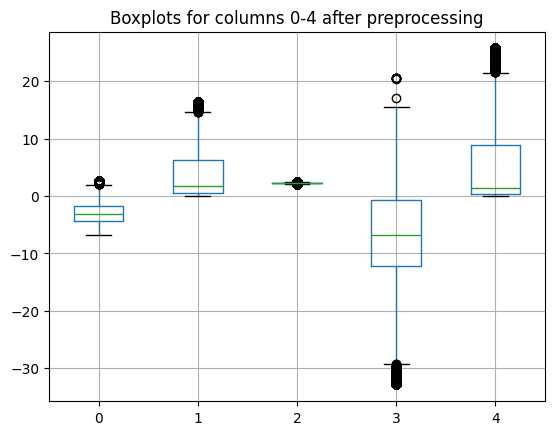

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

X_transformed = preprocessor.fit_transform(X_train)
num_features_out = numeric_features
cat_features_out = preprocessor.named_transformers_["cat"].get_feature_names_out(categorical_features)
all_columns = list(num_features_out) + list(cat_features_out)
X_train_transformed = pd.DataFrame(X_transformed, columns=all_columns, index=X_train.index)

X_train_transformed[['0', '1', '2', '3', '4']].boxplot()
plt.title('Boxplots for columns 0-4 after preprocessing')
plt.show()

Now, we are going to look at linear relationships between numerical columns and price

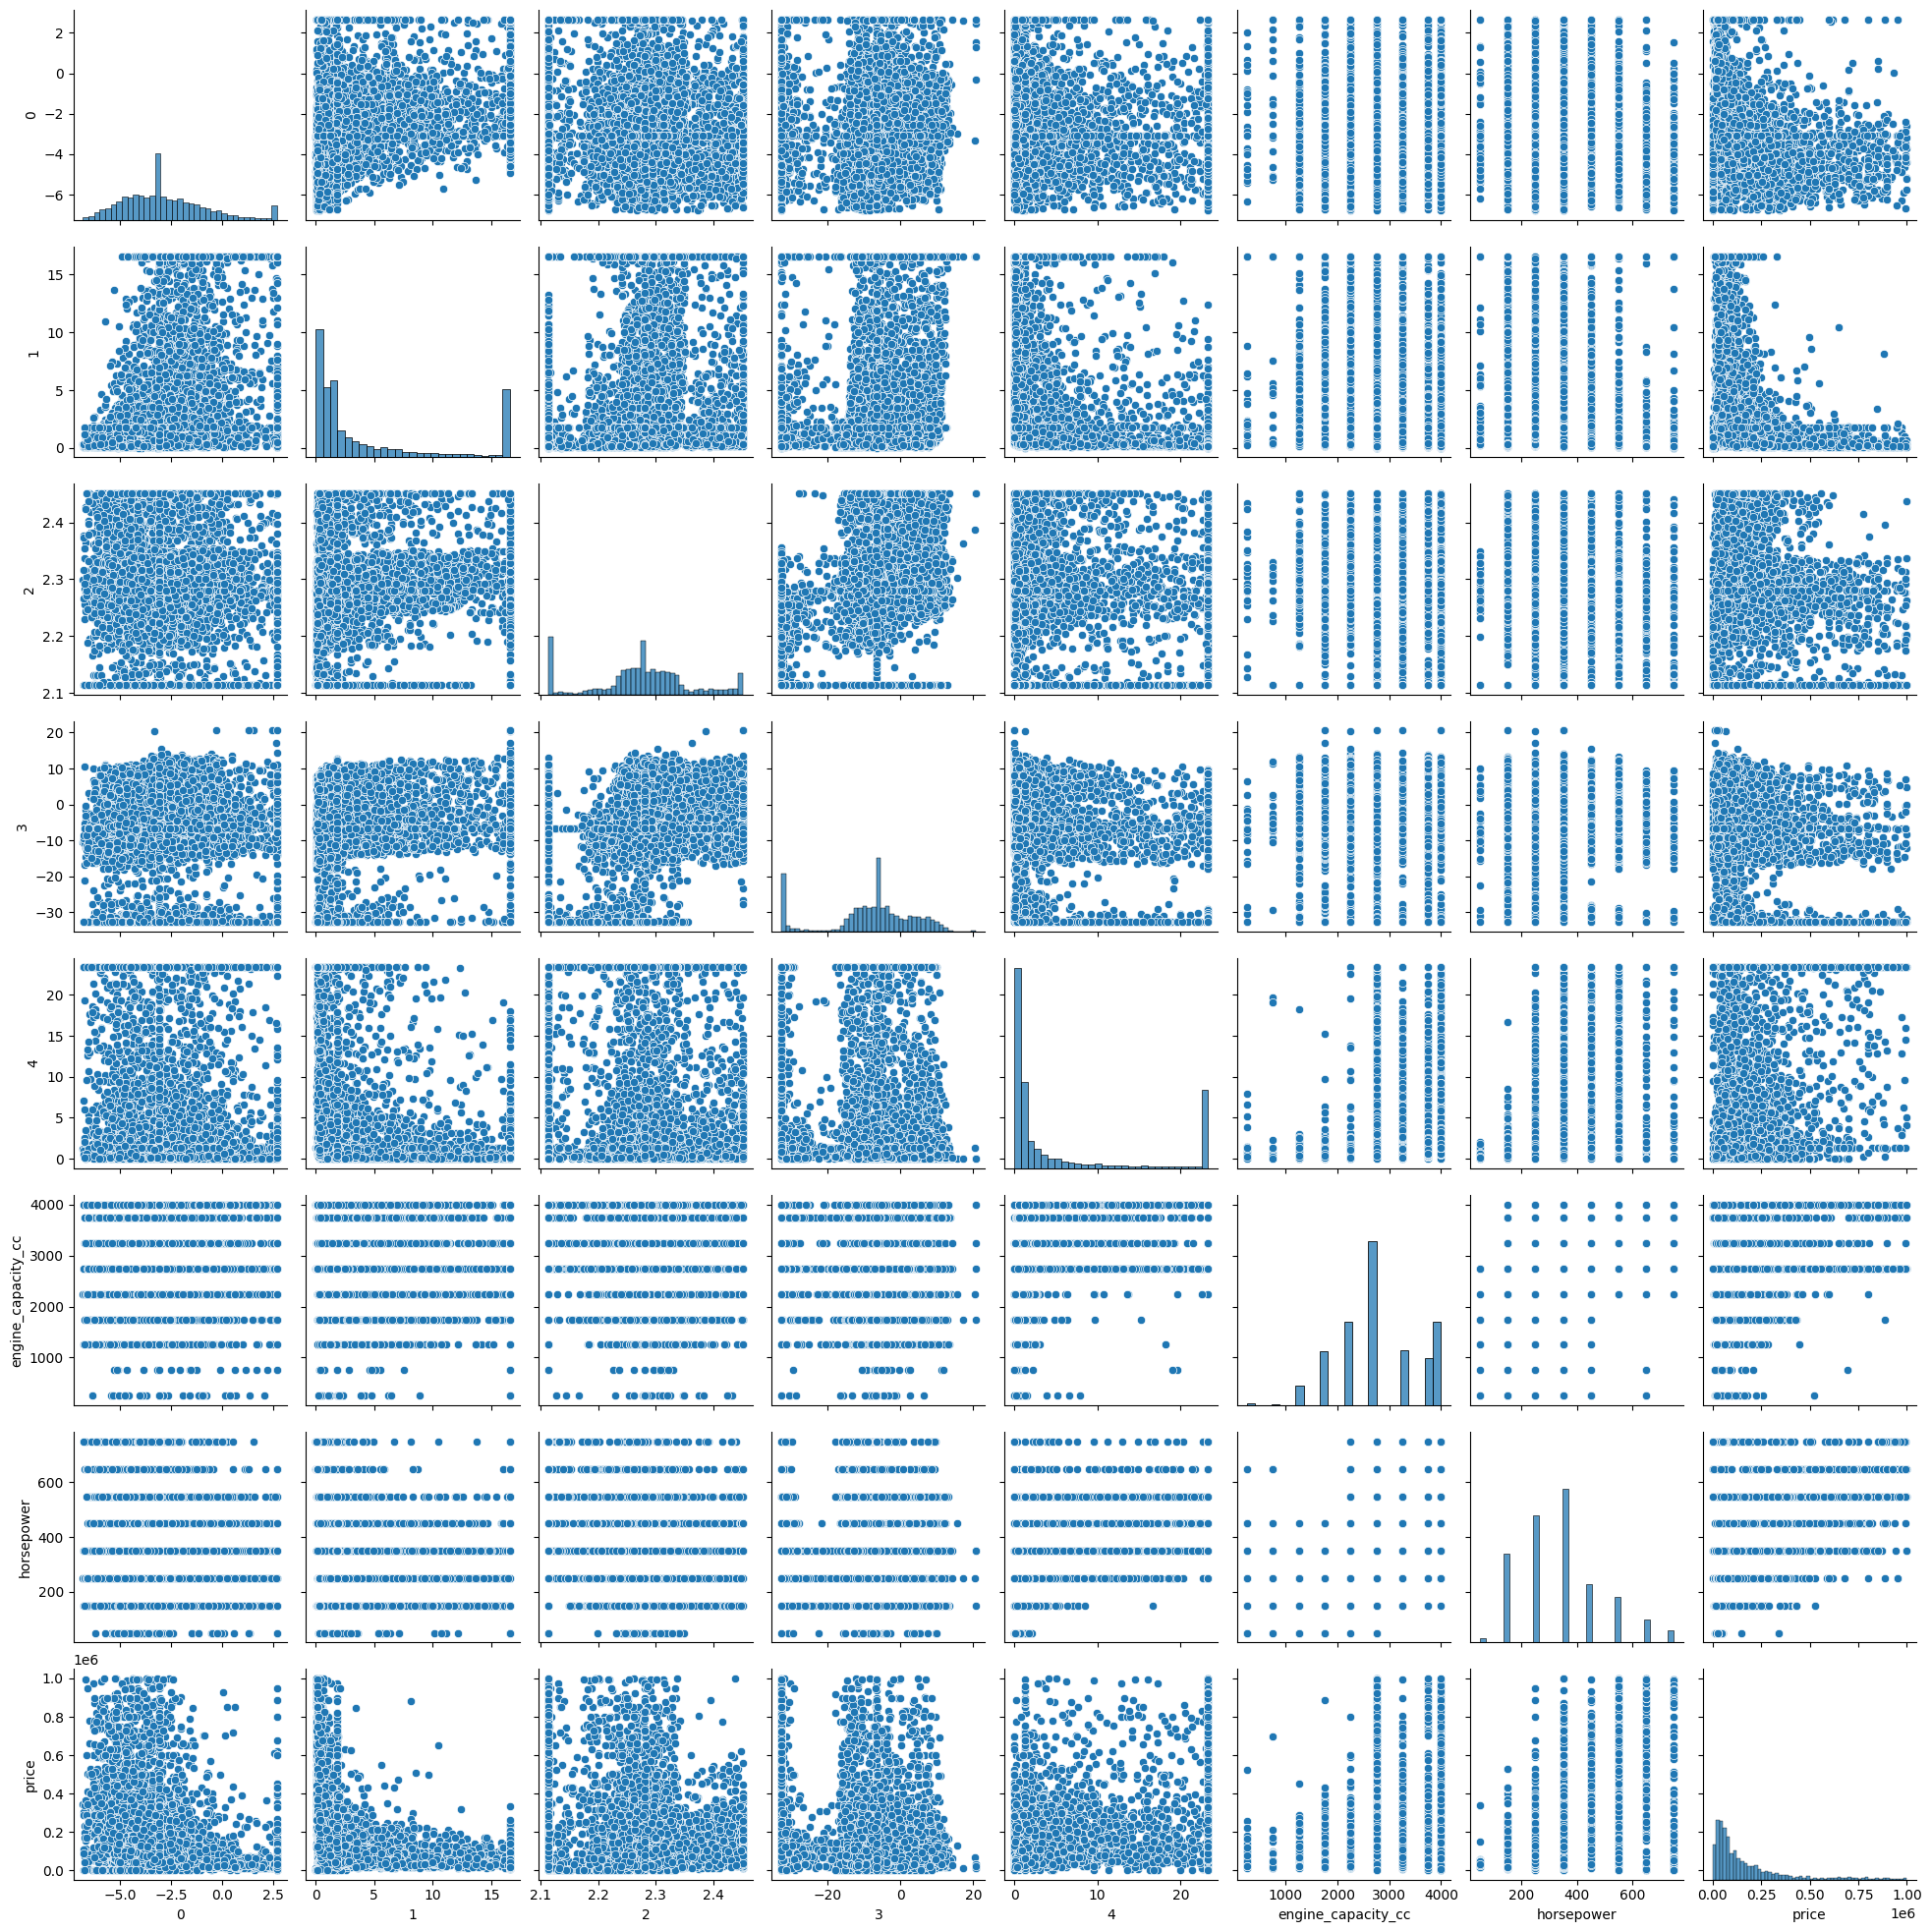

In [ ]:
import seaborn as sns

X_for_plot = pd.concat([X_train_transformed[['0', '1', '2', '3', '4', 'engine_capacity_cc','horsepower']], y_train], axis=1)
sns.pairplot(data=X_for_plot)
plt.show()

We see that apperently there is no linear dependence of price on numerical features. In order to conclude or dispute it, we'll also plot correlation matrix. From it, we'll see that there actually is linear dependence between price and other features, so training linear models on this data might be worthy. We also can't discern any patterns to apply any meaningful transformations to columns '0'-'4' (i.e. log1p(x) or 1/(1+x) )

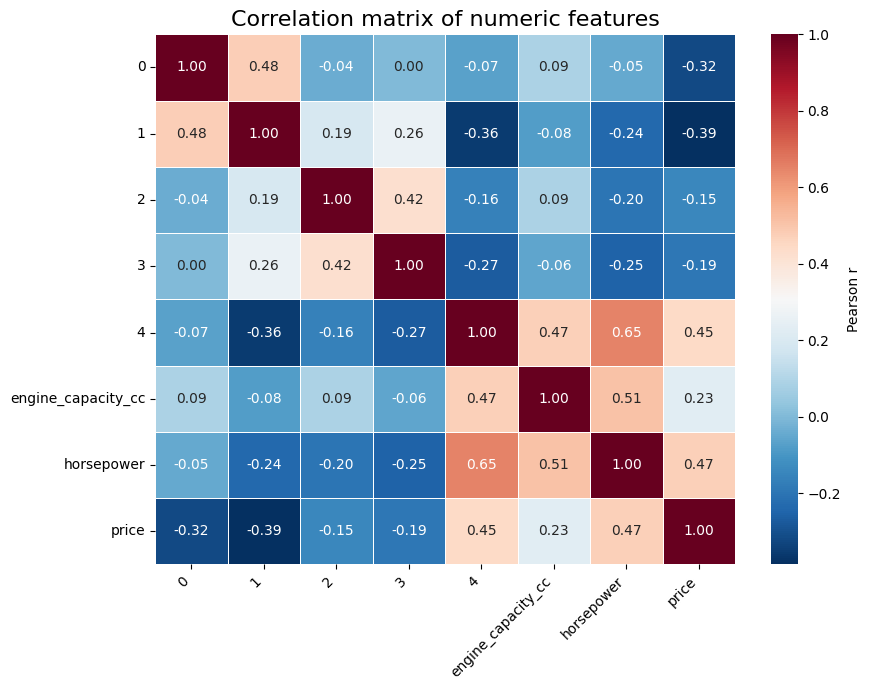

In [ ]:
corr = X_for_plot.corr()


plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    linewidths=0.5,
    cbar_kws={"label": "Pearson r"}
)
plt.title("Correlation matrix of numeric features", fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Categorical features

As seen from the previous section, there are too many unique categories in features 'brand', 'model', and 'trim'. We want to use only the most common of them.

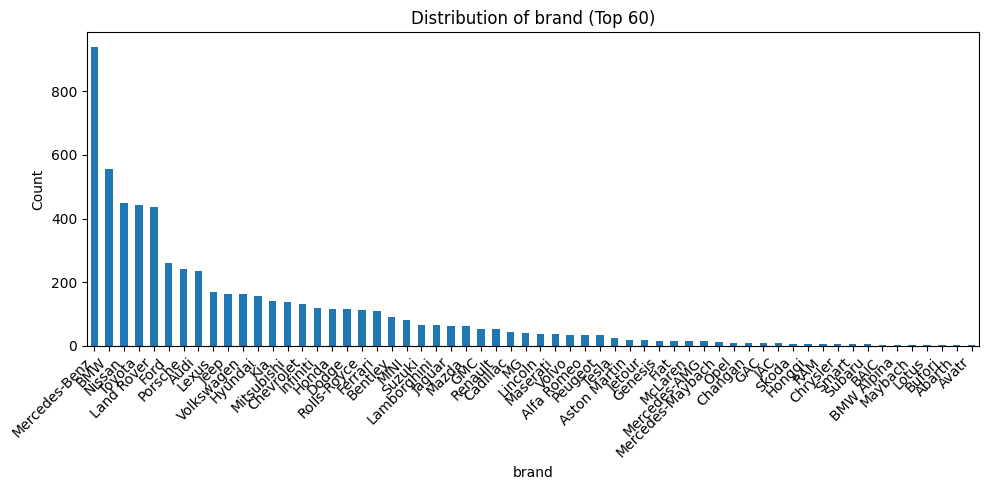

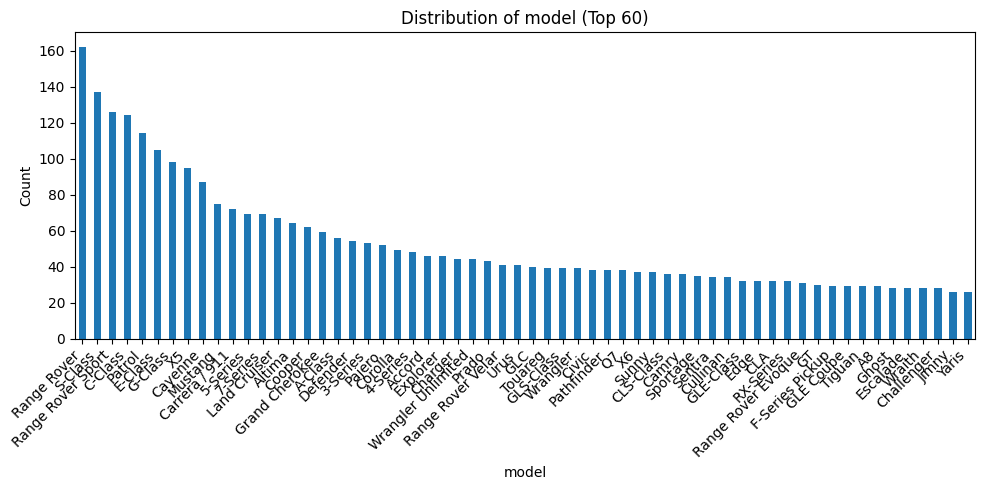

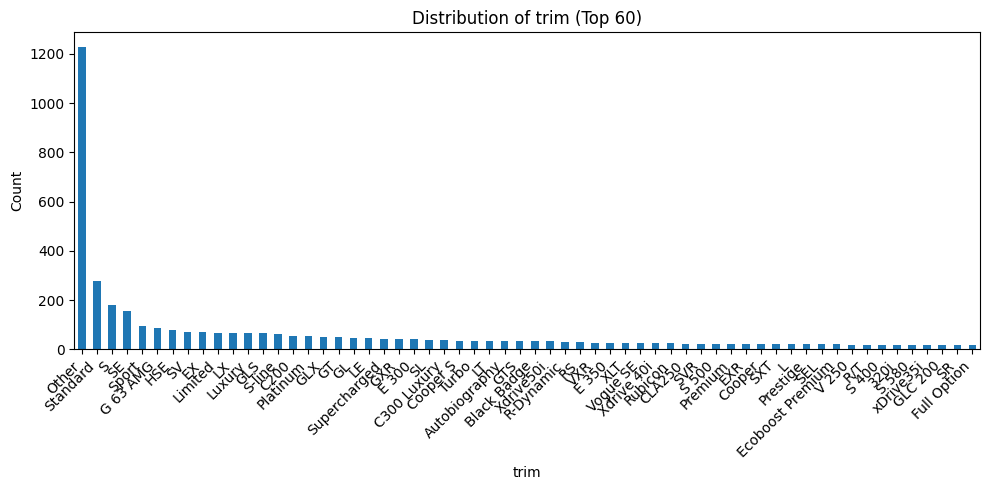

In [ ]:
import matplotlib.pyplot as plt

top_n = 60

for feature in ['brand','model','trim']:
    plt.figure(figsize=(10, 5))
    top_categories = X_train[feature].value_counts().nlargest(top_n)
    top_categories.plot(kind='bar')
    plt.title(f'Distribution of {feature} (Top {top_n})')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

As already mentioned, due to the very large number of categories, we cannot encode all the features using OneHotEncoder. Therefore, for feature 'trim', we'll keep only the most frequent values (60 of them), and rename the rest to 'other'; and for 'brand' and 'model' we want to use target encoding since from the experience we know that price is usually highly dependent on model and brand.

Now we'll train regression model.

#Our Models

##Linear Regression

In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import TargetEncoder

categorical_features_one_hot = [
    'body_type','fuel_type', 'transmission_type',
    'exterior_color','interior_color', 'warranty','city','seller_type'
]
categorical_features_target_encoding = ['brand', 'model']
numeric_features = ['0','1','2','3','4','engine_capacity_cc','horsepower']
number = 2

def parse_value(val, suffix):
    if pd.isna(val):
        return np.nan

    s = str(val).replace(suffix, '').strip()
    if s in ['Unknown']:
        return np.nan
    if '+' in s:
        return int(s.replace('+', '').strip())
    if '-' in s:
        low, high = s.split('-')
        return (float(low) + float(high)) / 2

    return float(s)

def parse_numeric_cols(X):
    X2 = X.copy()
    X2['engine_capacity_cc'] = X2['engine_capacity_cc'].apply(lambda v: parse_value(v, 'cc'))
    X2['horsepower'] = X2['horsepower'].apply(lambda v: parse_value(v, 'HP'))
    return X2

def clip_outliers(X):
    X_clipped = X.copy()

    for col_idx in range(X.shape[1]):

        col_data = X_clipped[:, col_idx]
        Q1 = np.nanquantile(col_data, 0.25)
        Q3 = np.nanquantile(col_data, 0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        X_clipped[:, col_idx] = np.clip(col_data, lower, upper)
    return X_clipped

parse_t = FunctionTransformer(parse_numeric_cols, validate=False)
clipper = FunctionTransformer(clip_outliers, validate=False)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imp",   SimpleImputer(strategy="median")),
        ("clip",  clipper),
        ("scale", StandardScaler())
    ]), numeric_features),
    ("cat_trim", OneHotEncoder(max_categories = 60, handle_unknown='infrequent_if_exist'), ["trim"]),
    ("cat_onehot", OneHotEncoder(handle_unknown="ignore"), categorical_features_one_hot),
    ("cat_target", TargetEncoder(target_type="continuous"), categorical_features_target_encoding)
], remainder='passthrough')

pipeline1 = Pipeline([
    ("parse", parse_t),
    ("prep",  preprocessor),
    ('linreg',   LinearRegression())
])

pipeline1.fit(X_train, y_train)

print("Train R2", pipeline1.score(X_train, y_train))
print("Test R2",pipeline1.score(X_test,  y_test))

print("RMSE", np.sqrt(mean_squared_error(y_test, pipeline1.predict(X_test))))

Train R2 0.5275905567766379
Test R2 0.4491130840377826
RMSE 128789.43041361652


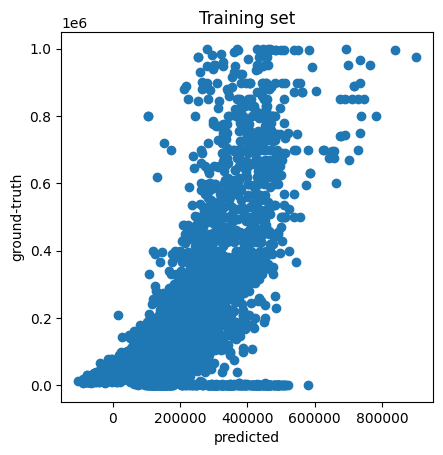

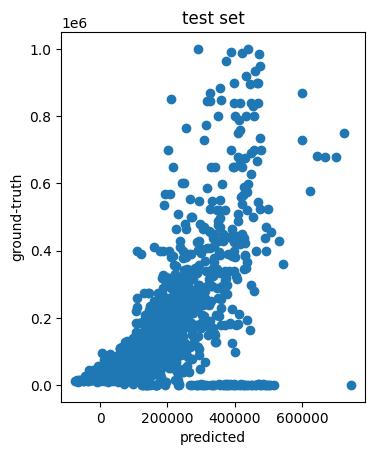

In [ ]:
from matplotlib import pyplot as plt
plt.scatter(pipeline1.predict(X_train), y_train)
plt.title("Training set")
plt.xlabel("predicted")
plt.ylabel("ground-truth")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()
plt.scatter(pipeline1.predict(X_test), y_test)
plt.title("test set")
plt.xlabel("predicted")
plt.ylabel("ground-truth")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

After playing around with different parameters we can see that we can raise r2 to a value of approximately 0.5. But unfortunately we cannot use this method in Lasso and Ridge, as its use with cross-validation will result in data leakage. Guided by the logic from above, we assume a relationship between the brand (model) and the price. In order to avoid overfitting, we replace rare brands (models) above the higher threshold price with "expensive brands (models)", and those below the lower threshold price with "cheap brands (models)". These parameters were selected just by brute-force (i.e. treated as hyperparameters).

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import FunctionTransformer

from sklearn.linear_model import LinearRegression
df = pd.read_csv('topic21_v33_train.csv')

x = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test =train_test_split(x,y,train_size=0.8,shuffle=True, random_state = 42)

X_train['trim'] = X_train['trim'].fillna('Other')

X_train.loc[
    X_train['trim'].map(X_train['trim'].value_counts()) < 2,
    'trim'
] = 'Other'

mask = X_train['model'].map(X_train['model'].value_counts()) < 2

X_train.loc[mask & (y_train < 50000), 'model'] = 'Cheap_model'
X_train.loc[mask & (y_train >= 50000), 'model'] = 'Expensive_model'

mask = X_train['brand'].map(X_train['brand'].value_counts()) < 20

X_train.loc[mask & (y_train< 50000), 'brand'] = 'Cheap_brand'
X_train.loc[mask & (y_train>= 50000), 'brand'] = 'Expensive_brand'

def parse_value(val, suffix):
    if pd.isna(val):
        return np.nan

    s = str(val).replace(suffix, '').strip()
    if s in ['Unknown']:
        return np.nan
    if '+' in s:
        return int(s.replace('+', '').strip())
    if '-' in s:
        low, high = s.split('-')
        return (float(low) + float(high)) / 2

    return float(s)


mask = y_train >= 1025

X_train = X_train[mask]
y_train = y_train[mask]

numeric_features = ['0','1','2','3','4','engine_capacity_cc','horsepower']
categorical_features = [
    'brand','model','trim','body_type','fuel_type',
    'transmission_type','exterior_color','interior_color',
    'warranty','city','seller_type'
]
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imp",   SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])


def parse_numeric_cols(X):
    X2 = X.copy()
    X2['engine_capacity_cc'] = X2['engine_capacity_cc'].apply(lambda v: parse_value(v, 'cc'))
    X2['horsepower'] = X2['horsepower'].apply(lambda v: parse_value(v, 'HP'))
    return X2
parse_t = FunctionTransformer(parse_numeric_cols, validate=False)
pipeline2 = Pipeline([
    ("parse", parse_t),
    ("prep",  preprocessor),
    ('linreg',   LinearRegression())
])
pipeline2.fit(X_train, y_train)

print("Train R2", pipeline2.score(X_train, y_train))
print("Test R2",pipeline2.score(X_test,  y_test))

print(np.sqrt(mean_squared_error(y_test, pipeline2.predict(X_test))))

Train R2 0.6340125066156301
Test R2 0.49071989090349877
123830.42139355898


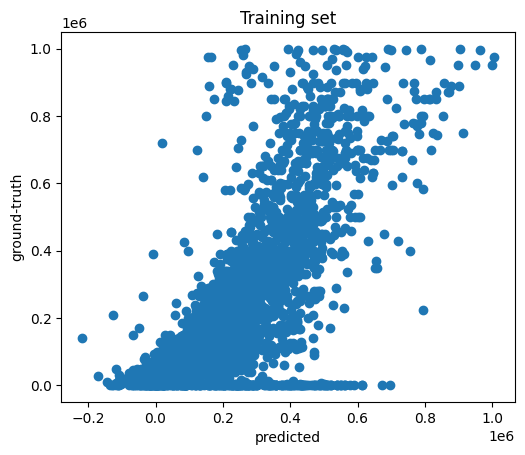

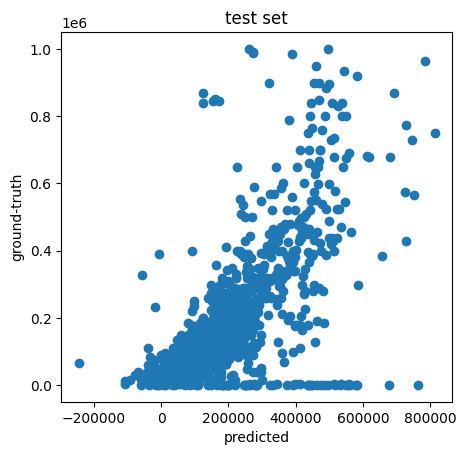

In [ ]:
from matplotlib import pyplot as plt
plt.scatter(pipeline2.predict(X_train), y_train)
plt.title("Training set")
plt.xlabel("predicted")
plt.ylabel("ground-truth")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()
plt.scatter(pipeline2.predict(X_test), y_test)
plt.title("test set")
plt.xlabel("predicted")
plt.ylabel("ground-truth")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

##Lasso

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV

X_train, X_test, y_train, y_test = train_test_split(x, y, train_size=0.8, shuffle=True, random_state=42)

pipeline3 = Pipeline([
    ("parse", parse_t),
    ("prep",  preprocessor),
    ("lasso", Lasso(max_iter=10000, random_state=42))
])

param_grid = {
    'lasso__alpha':10.0 ** np.array([-3, -2, -1, 0, 1, 2, 3])
}

grid1 = GridSearchCV(
    pipeline3,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid1.fit(X_train, y_train)

print("Best alpha:", grid1.best_params_['lasso__alpha'])

best_model = grid1.best_estimator_

y_train_pred = best_model.predict(X_train)
y_test_pred  = best_model.predict(X_test)

print(f"Train R2:  {r2_score(y_train, y_train_pred):.3f}")
print(f"Test R2:   {r2_score(y_test,  y_test_pred):.3f}")

print(f"Train RMSE:{np.sqrt(mean_squared_error(y_train, y_train_pred)):.2f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test,  y_test_pred)):.2f}")

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Best alpha: 100.0
Train R2:  0.565
Test R2:   0.476
Train RMSE:126511.82
Test RMSE: 125559.96


Now we will make a more careful selection of hyperparameter alpha:

In [ ]:
param_grid = {
    'lasso__alpha': [19, 20, 21, 22, 23, 24]
}

grid1 = GridSearchCV(
    pipeline3,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)
grid1.fit(X_train, y_train)
print("Best alpha:", grid1.best_params_['lasso__alpha'])

best_model = grid1.best_estimator_

y_train_pred = best_model.predict(X_train)
y_test_pred  = best_model.predict(X_test)

print(f"Train R2:  {r2_score(y_train, y_train_pred):.3f}")
print(f"Test R2:   {r2_score(y_test,  y_test_pred):.3f}")

print(f"Train RMSE:{np.sqrt(mean_squared_error(y_train, y_train_pred)):.2f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test,  y_test_pred)):.2f}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best alpha: 21
Train R2:  0.567
Test R2:   0.473
Train RMSE:126201.73
Test RMSE: 125908.75


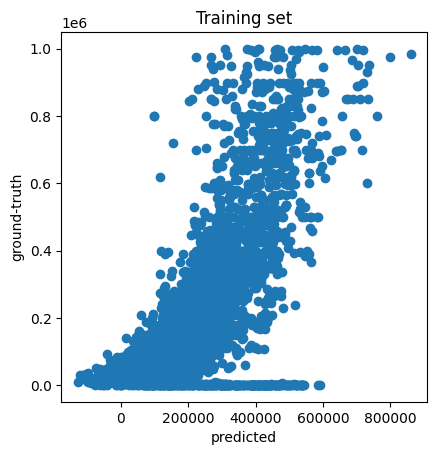

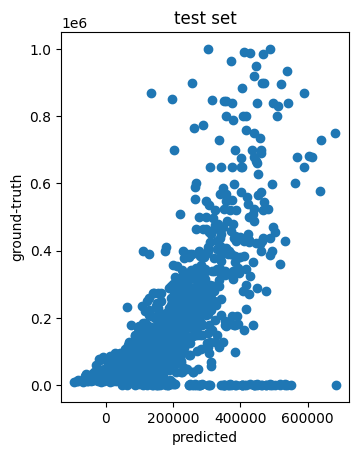

In [ ]:
from matplotlib import pyplot as plt
plt.scatter(grid1.predict(X_train), y_train)
plt.title("Training set")
plt.xlabel("predicted")
plt.ylabel("ground-truth")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()
plt.scatter(grid1.predict(X_test), y_test)
plt.title("test set")
plt.xlabel("predicted")
plt.ylabel("ground-truth")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

##Ridge

In [ ]:
from sklearn.linear_model import Ridge

pipeline4 = Pipeline([
    ("parse", parse_t),
    ("prep",  preprocessor),
    ("ridge", Ridge(max_iter=10000, random_state=42))
])

param_grid = {
    'ridge__alpha': 10.0 ** np.array([-4, -3, -2, -1, 0, 1, 2, 3, 4])
}

grid2 = GridSearchCV(
    pipeline4,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid2.fit(X_train, y_train)

print("Best alpha:", grid2.best_params_['ridge__alpha'])

best_model = grid2.best_estimator_

y_train_pred = best_model.predict(X_train)
y_test_pred  = best_model.predict(X_test)

print(f"Train R2:  {r2_score(y_train, y_train_pred):.3f}")
print(f"Test R2:   {r2_score(y_test,  y_test_pred):.3f}")

print(f"Train RMSE:{np.sqrt(mean_squared_error(y_train, y_train_pred)):.2f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test,  y_test_pred)):.2f}")

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best alpha: 10.0
Train R2:  0.479
Test R2:   0.409
Train RMSE:138424.18
Test RMSE: 133442.92


Now we will make a more careful selection of hyperparameter alpha:

In [ ]:
param_grid = {
    'ridge__alpha': [19, 20, 21, 22]
}

grid2 = GridSearchCV(
    pipeline4,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)
grid2.fit(X_train, y_train)
print("Best alpha:", grid2.best_params_['ridge__alpha'])

best_model = grid2.best_estimator_

y_train_pred = best_model.predict(X_train)
y_test_pred  = best_model.predict(X_test)

print(f"Train R2:  {r2_score(y_train, y_train_pred):.3f}")
print(f"Test R2:   {r2_score(y_test,  y_test_pred):.3f}")

print(f"Train RMSE:{np.sqrt(mean_squared_error(y_train, y_train_pred)):.2f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test,  y_test_pred)):.2f}")

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best alpha: 20
Train R2:  0.479
Test R2:   0.409
Train RMSE:138500.32
Test RMSE: 133431.90


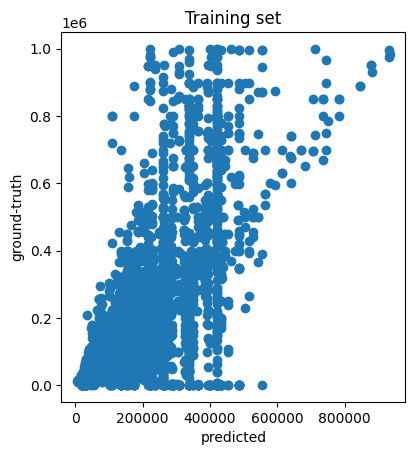

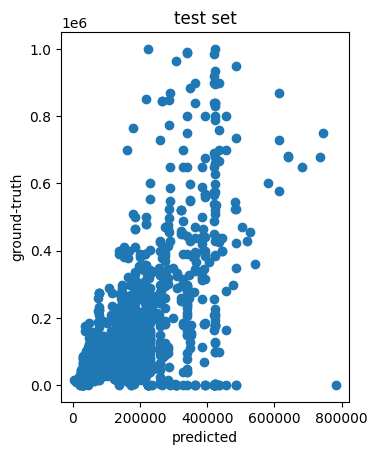

In [ ]:
from matplotlib import pyplot as plt
plt.scatter(grid2.predict(X_train), y_train)
plt.title("Training set")
plt.xlabel("predicted")
plt.ylabel("ground-truth")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()
plt.scatter(grid2.predict(X_test), y_test)
plt.title("test set")
plt.xlabel("predicted")
plt.ylabel("ground-truth")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

##RandomForestRegressor with OrdinalEncoding



In [ ]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor


parse_t = FunctionTransformer(parse_numeric_cols, validate=False)

numeric_features = ['0','1','2','3','4','engine_capacity_cc','horsepower']
categorical_features = [
    'brand','model','trim','body_type','fuel_type',
    'transmission_type','exterior_color','interior_color',
    'warranty','city','seller_type'
]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imp",   SimpleImputer(strategy="median")),
    ]), numeric_features),
    ("cat", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ), categorical_features),
])

pipeline = Pipeline([
    ("parse", parse_t),
    ("prep",  preprocessor),
    ("rf",    RandomForestRegressor(random_state=42, n_jobs=-1))
])

param_grid = {
    "rf__n_estimators":     [1200, 1500, 1700],
    "rf__max_depth":        [10, 20, 30],
    "rf__min_samples_split": [1, 2, 3],
    "rf__min_samples_leaf":  [1, 2, 3],
    "rf__max_features":      [0.3, 0.5, 0.7],

}

grid1 = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

grid1.fit(X_train, y_train)

print("Best params:", grid1.best_params_)

best_rf = grid1.best_estimator_

y_train_pred = best_rf.predict(X_train)
y_test_pred  = best_rf.predict(X_test)

print(f"Train R2:   {r2_score(y_train, y_train_pred):.3f}")
print(f"Test  R2:   {r2_score(y_test,  y_test_pred):.3f}")
print(f"Train RMSE: {np.sqrt(mean_squared_error(y_train, y_train_pred)):.2f}")
print(f"Test  RMSE: {np.sqrt(mean_squared_error(y_test,  y_test_pred)):.2f}")

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Best params: {'rf__max_depth': 20, 'rf__max_features': 0.3, 'rf__min_samples_leaf': 1, 'rf__min_samples_split': 2, 'rf__n_estimators': 1500}
Train R2:   0.933
Test  R2:   0.583
Train RMSE: 49161.63
Test  RMSE: 116682.48


##GradientBoostingRegressor

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import GradientBoostingRegressor

df = pd.read_csv('topic21_v33_train (4).csv')
X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.8, shuffle=True, random_state=42
)


def parse_value(val, suffix):
    if pd.isna(val):
        return np.nan

    s = str(val).replace(suffix, '').strip()
    if s in ['Unknown']:
        return np.nan
    if '+' in s:
        return int(s.replace('+', '').strip())
    if '-' in s:
        low, high = s.split('-')
        return (float(low) + float(high)) / 2
    try:
        return float(s)
    except ValueError:
        return np.nan
def parse_numeric_cols(X):
    X2 = X.copy()
    X2['engine_capacity_cc'] = X2['engine_capacity_cc'].apply(lambda v: parse_value(v, 'cc'))
    X2['horsepower'] = X2['horsepower'].apply(lambda v: parse_value(v, 'HP'))
    return X2


parse_t = FunctionTransformer(parse_numeric_cols, validate=False)

numeric_features = ['0','1','2','3','4','engine_capacity_cc','horsepower']
categorical_features = [
    'brand','model','trim','body_type','fuel_type',
    'transmission_type','exterior_color','interior_color',
    'warranty','city','seller_type'
]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median"))
    ]), numeric_features),

    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="missing")),
        ("ord", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), categorical_features)
])



pipeline = Pipeline([
    ('parse', FunctionTransformer(parse_numeric_cols, validate=False)),
    ('prep',  preprocessor),
    ('gbr',   GradientBoostingRegressor(random_state=42))
])
n = [100, 200, 300, 400, 500, 600, 700, 800, 900]
param_grid = {
    'gbr__n_estimators': n,
    'gbr__learning_rate': [ 0.1],
    'gbr__max_depth': [5],
}

grid5 = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid5.fit(X_train, y_train)

print("Best params:", grid5.best_params_)

best_rf = grid5.best_estimator_

y_train_pred = best_rf.predict(X_train)
y_test_pred  = best_rf.predict(X_test)
cv_res = grid5.cv_results_
for n_est, r2_mean, r2_std in zip(cv_res['param_gbr__n_estimators'],
                                  cv_res['mean_test_score'],
                                  cv_res['std_test_score']):
    print(f"n_estimators = {n_est:>3} | mean CV R2 = {r2_mean:6.3f} ± {r2_std:5.3f}")

print("\nBest params:", grid5.best_params_)

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best params: {'gbr__learning_rate': 0.1, 'gbr__max_depth': 5, 'gbr__n_estimators': 400}
n_estimators = 100 | mean CV R2 =  0.515 ± 0.013
n_estimators = 200 | mean CV R2 =  0.525 ± 0.013
n_estimators = 300 | mean CV R2 =  0.525 ± 0.012
n_estimators = 400 | mean CV R2 =  0.525 ± 0.012
n_estimators = 500 | mean CV R2 =  0.525 ± 0.012
n_estimators = 600 | mean CV R2 =  0.524 ± 0.012
n_estimators = 700 | mean CV R2 =  0.523 ± 0.011
n_estimators = 800 | mean CV R2 =  0.524 ± 0.012
n_estimators = 900 | mean CV R2 =  0.523 ± 0.011

Best params: {'gbr__learning_rate': 0.1, 'gbr__max_depth': 5, 'gbr__n_estimators': 400}


In [ ]:
s = [0.1, 0.3, 0.5, 0.7, 0.9, 1.1]
param_grid = {
    'gbr__n_estimators': [400],
    'gbr__learning_rate': s,
    'gbr__max_depth': [5],
}

grid5 = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid5.fit(X_train, y_train)

print("Best params:", grid5.best_params_)

best_rf = grid5.best_estimator_

y_train_pred = best_rf.predict(X_train)
y_test_pred  = best_rf.predict(X_test)

print("\nBest params:", grid5.best_params_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best params: {'gbr__learning_rate': 0.1, 'gbr__max_depth': 5, 'gbr__n_estimators': 400}

Best params: {'gbr__learning_rate': 0.1, 'gbr__max_depth': 5, 'gbr__n_estimators': 400}


In [ ]:
s = [2, 4, 6, 7, 8]
param_grid = {
    'gbr__n_estimators': [400],
    'gbr__learning_rate': [0.1],
    'gbr__max_depth': s,
}

grid5 = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid5.fit(X_train, y_train)

print("Best params:", grid5.best_params_)

best_rf = grid5.best_estimator_

y_train_pred = best_rf.predict(X_train)
y_test_pred  = best_rf.predict(X_test)

print("\nBest params:", grid5.best_params_)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best params: {'gbr__learning_rate': 0.1, 'gbr__max_depth': 7, 'gbr__n_estimators': 400}

Best params: {'gbr__learning_rate': 0.1, 'gbr__max_depth': 7, 'gbr__n_estimators': 400}


In [ ]:
parse_t = FunctionTransformer(parse_numeric_cols, validate=False)

numeric_features = ['0','1','2','3','4','engine_capacity_cc','horsepower']
categorical_features = [
    'brand','model','trim','body_type','fuel_type',
    'transmission_type','exterior_color','interior_color',
    'warranty','city','seller_type'
]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median"))
    ]), numeric_features),

    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="missing")),
        ("ord", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), categorical_features)
])



pipeline = Pipeline([
    ('parse', FunctionTransformer(parse_numeric_cols, validate=False)),
    ('prep',  preprocessor),
    ('gbr',   GradientBoostingRegressor(random_state=42))
])

param_grid = {
    'gbr__n_estimators': [400],
    'gbr__learning_rate': [0.1],
    'gbr__max_depth': [7],
}

grid5 = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid5.fit(X_train, y_train)


best_rf = grid5.best_estimator_

y_train_pred = best_rf.predict(X_train)
y_test_pred  = best_rf.predict(X_test)

print(f"Train R2:   {r2_score(y_train, y_train_pred):.3f}")
print(f"Test  R2:   {r2_score(y_test,  y_test_pred):.3f}")
print(f"Train RMSE: {np.sqrt(mean_squared_error(y_train, y_train_pred)):.2f}")
print(f"Test  RMSE: {np.sqrt(mean_squared_error(y_test,  y_test_pred)):.2f}")

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Train R2:   0.994
Test  R2:   0.573
Train RMSE: 14737.34
Test  RMSE: 113322.69
